> **Variante _sin recorte aleatorio_ de `other_experiments/02.1_train_resnet152.ipynb`.**
> Las entradas son siempre fondos de ojo **completos**: un `RandomResizedCrop(scale=(0.7, 1.0))` puede dejar fuera lesiones periféricas, el disco óptico o la mácula, y además deforma la proporción de la imagen. Aquí se sustituye por un **letterbox** (lado largo = `image_size`, relleno negro hasta cuadrado), aplicado **igual en train, val, test y Grad-CAM** (`TrainConfig.preprocessing = "letterbox"`).
> Se reutilizan **los mismos hiperparámetros de Optuna** (`best_params.json`, encontrados con el recorte aleatorio) y las mismas épocas, de modo que la única diferencia con el original es el preprocesado. Los modelos originales (`best_resnet152_disease_risk.pt` y `..._optuna.pt`) **no se reentrenan ni se modifican**: se cargan y se evalúan con *su* preprocesado original. Si falta alguno (incluido el baseline nocrop de `02_train_resnet152_nocrop.ipynb`), se omite de la comparación con un aviso.
> Salidas con sufijo `_nocrop`: checkpoint `best_resnet152_disease_risk_optuna_nocrop.pt`, historial `artifacts/logs/tuned_nocrop_history.json`, figuras `artifacts/figures/tuned_nocrop_*.png` y Grad-CAM en `artifacts/gradcam/nocrop/`.

# RFMiD — ResNet-152 con los hiperparámetros de Optuna (Disease_Risk), sin RandomResizedCrop

1. Carga los mejores hiperparámetros de `artifacts/optuna/best_params.json` (notebook `03`).
2. Entrena el modelo final: `train_loss` y `val_loss` por época, *early stopping* y checkpoint por **`val_loss` mínima** (no por AUC) en un archivo **nuevo** (`best_resnet152_disease_risk_optuna_nocrop.pt`), sin tocar los anteriores.
3. Evalúa en **test**; el umbral de decisión se elige **solo en validación** (índice de Youden) y se compara: baseline original, ajustado original, baseline nocrop y ajustado nocrop.
4. Grad-CAM sobre el modelo ajustado nocrop.

**Criterio de selección = `val_loss` (se minimiza).** El mejor checkpoint y el *early stopping* (paciencia 7) usan la pérdida focal de **validación** (`selection_metric="val_loss"`). Se descarta `train_loss` porque baja casi siempre con las épocas y elegiría la más sobreajustada; `val_loss` sí mide generalización. Como el scheduler ajustado de Optuna es `ReduceLROnPlateau`, en esta variante monitoriza también `val_loss` (modo `min`) para que LR, checkpoint y *early stopping* usen la misma señal (en el resto de notebooks sigue monitorizando el AUC). AUC, F1 y accuracy se siguen calculando y reportando como métricas de evaluación, y el umbral de decisión se sigue eligiendo solo en validación.

**Nota de cómputo:** sin GPU (CPU, 4 hilos). Con `layer3` descongelado una época a 224 px tarda ~20 min, así que el entrenamiento final se limita a **10 épocas** (`EPOCHS_FINAL`), igual que en `other_experiments/02.1_train_resnet152.ipynb`.

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

# Localiza retina_clasificacion/ aunque el cwd del kernel sea el padre Retina/
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
if _cwd.is_dir():
    _candidates.extend(sorted(path for path in _cwd.iterdir() if path.is_dir()))
PROJECT_ROOT = next(
    directory
    for directory in _candidates
    if (directory / "src" / "config.py").is_file() and (directory / "requirements.txt").is_file()
)
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != PROJECT_ROOT]
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("TORCH_HOME", str(PROJECT_ROOT / "artifacts" / "torch_cache"))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

from src.config import default_config
from src.data import PREPROCESSING_LETTERBOX, PREPROCESSING_RANDOM_CROP, create_dataloaders
from src.evaluate import (
    collect_predictions,
    compute_classification_metrics,
    select_threshold_youden,
)
from src.explain import compute_gradcam_samples, plot_gradcam_grid
from src.model import load_model
from src.train import get_device, train_model
from src.tuning import build_final_config

device = get_device()
print(f"device={device}")

device=cpu


C:\Users\Xabat Arin\miniconda3\envs\dl\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Hiperparámetros encontrados por Optuna

In [2]:
EPOCHS_FINAL = 10  # igual que 02.1 (20 en el baseline); reducido por coste en CPU
TUNED_CHECKPOINT_NAME = "best_resnet152_disease_risk_optuna.pt"  # original, solo se lee
BASELINE_NOCROP_CHECKPOINT_NAME = "best_resnet152_disease_risk_nocrop.pt"  # de 02_..._nocrop
TUNED_NOCROP_CHECKPOINT_NAME = "best_resnet152_disease_risk_optuna_nocrop.pt"

best_params_payload = json.loads(
    (PROJECT_ROOT / "artifacts" / "optuna" / "best_params.json").read_text(encoding="utf-8")
)
best_params = best_params_payload["best_params"]
print(f"AUC de validación en la búsqueda (régimen reducido): {best_params_payload['best_val_auc_reduced_regime']:.4f}")
pd.Series(best_params, name="valor").to_frame()

AUC de validación en la búsqueda (régimen reducido): 0.9432


,valor
learning_rate,0.000462
weight_decay,0.000007
focal_gamma,1.36365
focal_alpha,0.260043
batch_size,16
unfreeze_layer3,True
lr_scheduler,plateau


In [3]:
# Configuraciones originales (preprocesado random_crop): solo para evaluar sus checkpoints
baseline_config = default_config()
tuned_config = build_final_config(baseline_config, best_params, TUNED_CHECKPOINT_NAME)
tuned_config.epochs = EPOCHS_FINAL

# Variantes nocrop: mismos hiperparámetros; cambian preprocesado, nombre del checkpoint y
# criterio de selección (val_loss, a minimizar, en lugar de AUC). baseline_nocrop_config solo
# se usa para cargar el checkpoint entrenado en 02_..._nocrop (con el mismo criterio).
SELECTION_METRIC = "val_loss"
baseline_nocrop_config = replace(
    baseline_config,
    preprocessing=PREPROCESSING_LETTERBOX,
    best_checkpoint_name=BASELINE_NOCROP_CHECKPOINT_NAME,
    selection_metric=SELECTION_METRIC,
)
tuned_nocrop_config = replace(
    tuned_config,
    preprocessing=PREPROCESSING_LETTERBOX,
    best_checkpoint_name=TUNED_NOCROP_CHECKPOINT_NAME,
    selection_metric=SELECTION_METRIC,
)

print(
    f"epochs={tuned_nocrop_config.epochs}, batch_size={tuned_nocrop_config.batch_size}, "
    f"lr={tuned_nocrop_config.learning_rate:.2e}, scheduler={tuned_nocrop_config.lr_scheduler}, "
    f"unfreeze_layer3={tuned_nocrop_config.unfreeze_layer3}, image_size={tuned_nocrop_config.image_size}, "
    f"preprocessing={tuned_nocrop_config.preprocessing}, selection_metric={tuned_nocrop_config.selection_metric}"
)

(
    train_loader,
    val_loader,
    test_loader,
    train_dataframe,
    val_dataframe,
    test_dataframe,
) = create_dataloaders(tuned_nocrop_config)
for name, dataframe in [("train", train_dataframe), ("val", val_dataframe), ("test", test_dataframe)]:
    print(name, len(dataframe), dataframe["disease_risk"].value_counts().to_dict())

# Loaders con el preprocesado ORIGINAL (resize cuadrado) para evaluar los modelos originales
original_val_loader, original_test_loader = create_dataloaders(tuned_config)[1:3]

epochs=10, batch_size=16, lr=4.62e-04, scheduler=plateau, unfreeze_layer3=True, image_size=224, preprocessing=letterbox, selection_metric=val_loss
train 1920 {1: 1519, 0: 401}
val 640 {1: 506, 0: 134}
test 640 {1: 506, 0: 134}


## 2. Entrenamiento final

Cada época imprime `train_loss` y `val_loss`; el mejor checkpoint y el *early stopping* se rigen por `val_loss` mínima. Si ya existe el checkpoint ajustado nocrop no se reentrena (el historial se recarga de `artifacts/logs/tuned_nocrop_history.json`).

In [4]:
FORCE_RETRAIN = False

tuned_checkpoint_path = tuned_nocrop_config.checkpoint_dir / tuned_nocrop_config.best_checkpoint_name
history_path = PROJECT_ROOT / "artifacts" / "logs" / "tuned_nocrop_history.json"
history_path.parent.mkdir(parents=True, exist_ok=True)

if FORCE_RETRAIN or not (tuned_checkpoint_path.is_file() and history_path.is_file()):
    training_history: list[dict] = []
    train_model(train_loader, val_loader, tuned_nocrop_config, history=training_history)
    history_path.write_text(json.dumps(training_history, indent=2), encoding="utf-8")
else:
    training_history = json.loads(history_path.read_text(encoding="utf-8"))
    print(f"Checkpoint existente, se omite el entrenamiento: {tuned_checkpoint_path}")

Dispositivo: cpu
Backbone: ResNet-152 (no existe ResNet-150 en torchvision)
Épocas: 10
Parámetros entrenables: 55,580,673 / 58,145,857
Política de congelación:
  - conv1: congelado
  - bn1: congelado
  - relu: sin parámetros
  - maxpool: sin parámetros
  - layer1: congelado
  - layer2: congelado
  - layer3: entrenable
  - layer4: entrenable
  - avgpool: sin parámetros
  - fc: entrenable


train:   0%|          | 0/120 [00:00<?, ?it/s]

train:   1%|          | 1/120 [00:08<17:11,  8.66s/it]

train:   2%|▏         | 2/120 [00:17<17:07,  8.71s/it]

train:   2%|▎         | 3/120 [00:26<17:20,  8.89s/it]

...

eval:  95%|█████████▌| 38/40 [02:59<00:11,  5.88s/it]

eval:  98%|█████████▊| 39/40 [03:07<00:06,  6.68s/it]

eval: 100%|██████████| 40/40 [03:16<00:00,  7.36s/it]

Epoch 10/10 | train_loss=0.0360 | val_loss=0.0453 | AUC=0.9375 | F1=0.8983 | Acc=0.8500


  → Nuevo mejor modelo (val_loss=0.0453) guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\checkpoints\best_resnet152_disease_risk_optuna_nocrop.pt
Mejor val_loss de validación: 0.0453


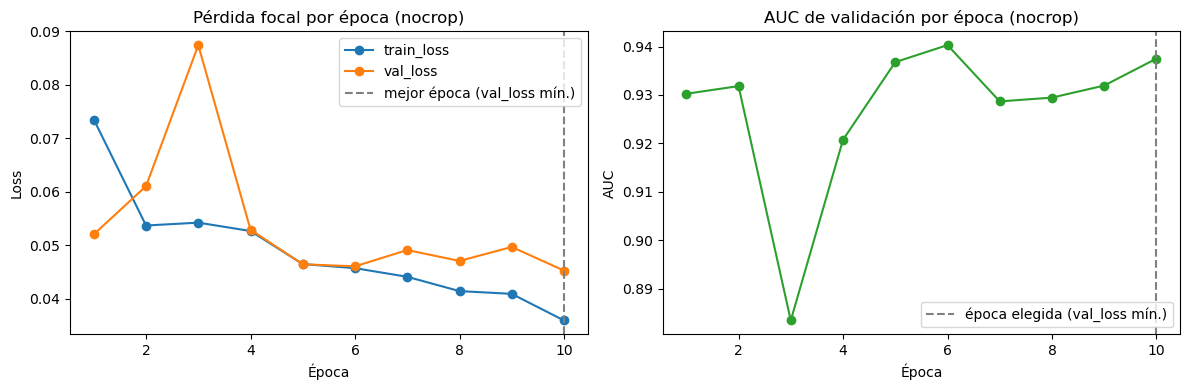

,train_loss,val_loss,val_auc,val_f1,val_accuracy,learning_rate,epoch_seconds
epoch,,,,,,,
1,0.0735,0.0521,0.9303,0.8822,0.8297,0.0005,1357.6329
2,0.0537,0.0611,0.9318,0.8383,0.7781,0.0005,1351.9930
3,0.0543,0.0874,0.8835,0.7546,0.6859,0.0005,1366.0879
4,0.0527,0.0529,0.9208,0.8619,0.8047,0.0005,1354.5720
5,0.0465,0.0465,0.9368,0.8826,0.8312,0.0002,1360.8876
6,0.0457,0.0461,0.9403,0.9033,0.8578,0.0002,1374.1123
7,0.0441,0.0491,0.9287,0.8872,0.8375,0.0002,1358.8792
8,0.0415,0.0471,0.9295,0.9061,0.8578,0.0002,1354.7757
9,0.0409,0.0497,0.9320,0.9168,0.8688,0.0002,1349.1970


In [5]:
history_table = pd.DataFrame(training_history).set_index("epoch")
figure, (loss_axis, auc_axis) = plt.subplots(1, 2, figsize=(12, 4))

loss_axis.plot(history_table.index, history_table["train_loss"], marker="o", label="train_loss")
loss_axis.plot(history_table.index, history_table["val_loss"], marker="o", label="val_loss")
# Época elegida por el criterio de selección: val_loss mínima
selected_epoch = history_table["val_loss"].idxmin()
loss_axis.axvline(selected_epoch, color="gray", linestyle="--", label="mejor época (val_loss mín.)")
loss_axis.set(title="Pérdida focal por época (nocrop)", xlabel="Época", ylabel="Loss")
loss_axis.legend()

auc_axis.plot(history_table.index, history_table["val_auc"], marker="o", color="tab:green")
auc_axis.axvline(selected_epoch, color="gray", linestyle="--", label="época elegida (val_loss mín.)")
auc_axis.set(title="AUC de validación por época (nocrop)", xlabel="Época", ylabel="AUC")
auc_axis.legend()

plt.tight_layout()
figures_dir = PROJECT_ROOT / "artifacts" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "tuned_nocrop_training_curves.png", dpi=110)
plt.show()
history_table.round(4)

## 3. Evaluación: baseline vs ajustado, original vs nocrop

Se calculan las probabilidades de cada modelo en val y test, **con el preprocesado con el que fue entrenado** (resize cuadrado para los originales, letterbox para los nocrop). El **umbral se elige en validación** (índice de Youden: maximiza TPR − FPR, más adecuado que F1 con 79 % de positivos) y se aplica sin cambios a test. Se incluye también el umbral fijo 0.5. El AUC no depende del umbral.

In [6]:
# nombre del modelo -> config con la que se entrenó (fija checkpoint y preprocesado)
model_configs = {
    "baseline (original)": baseline_config,
    "ajustado (original)": tuned_config,
    "baseline nocrop": baseline_nocrop_config,
    "ajustado nocrop": tuned_nocrop_config,
}
# Cada modelo se evalúa con loaders que usan SU preprocesado
evaluation_loaders = {
    PREPROCESSING_RANDOM_CROP: (original_val_loader, original_test_loader),
    PREPROCESSING_LETTERBOX: (val_loader, test_loader),
}
TUNED_NOCROP_NAME = "ajustado nocrop"

predictions = {}
tuned_model = None
for model_name, model_config in model_configs.items():
    checkpoint_path = model_config.checkpoint_dir / model_config.best_checkpoint_name
    if not checkpoint_path.is_file():
        print(f"AVISO: no existe {checkpoint_path}; '{model_name}' se omite de la comparación.")
        continue

    model = load_model(checkpoint_path, model_config, device)
    model_val_loader, model_test_loader = evaluation_loaders[model_config.preprocessing]
    val_probabilities, val_labels, _ = collect_predictions(model, model_val_loader, device)
    test_probabilities, test_labels, _ = collect_predictions(model, model_test_loader, device)
    predictions[model_name] = {
        "val_probabilities": val_probabilities,
        "val_labels": val_labels,
        "test_probabilities": test_probabilities,
        "test_labels": test_labels,
        # Umbral elegido SOLO con validación
        "threshold": select_threshold_youden(val_probabilities, val_labels),
    }
    print(f"{model_name}: umbral (Youden, val) = {predictions[model_name]['threshold']:.3f}")

    # Solo se conserva en memoria el modelo que se usará en Grad-CAM
    if model_name == TUNED_NOCROP_NAME:
        tuned_model = model
    else:
        del model

eval:   0%|          | 0/40 [00:00<?, ?it/s]

eval:   2%|▎         | 1/40 [00:04<03:03,  4.70s/it]

eval:   5%|▌         | 2/40 [00:08<02:46,  4.39s/it]

eval:   8%|▊         | 3/40 [00:13<02:38,  4.29s/it]

eval:  10%|█         | 4/40 [00:17<02:31,  4.22s/it]

...

eval:  92%|█████████▎| 37/40 [03:05<00:17,  5.72s/it]

eval:  95%|█████████▌| 38/40 [03:13<00:13,  6.52s/it]

eval:  98%|█████████▊| 39/40 [03:19<00:06,  6.33s/it]

eval: 100%|██████████| 40/40 [03:26<00:00,  6.72s/it]

ajustado nocrop: umbral (Youden, val) = 0.545


In [7]:
comparison_rows = []
for model_name, model_predictions in predictions.items():
    for split_name in ("val", "test"):
        probabilities = model_predictions[f"{split_name}_probabilities"]
        labels = model_predictions[f"{split_name}_labels"]
        for threshold_name, threshold in [("0.5", 0.5), ("val-Youden", model_predictions["threshold"])]:
            metrics = compute_classification_metrics(probabilities, labels, threshold=threshold)
            comparison_rows.append(
                {
                    "modelo": model_name,
                    "split": split_name,
                    "umbral": f"{threshold_name} ({threshold:.3f})",
                    "AUC": metrics["auc"],
                    "F1": metrics["f1"],
                    "Accuracy": metrics["accuracy"],
                    "matriz_confusion": metrics["confusion_matrix"],
                }
            )
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.round(4)

,modelo,split,umbral,AUC,F1,Accuracy,matriz_confusion
0,baseline (original),val,0.5 (0.500),0.9313,0.9015,0.8531,"[[116, 18], [76, 430]]"
1,baseline (original),val,val-Youden (0.609),0.9313,0.8794,0.8281,"[[129, 5], [105, 401]]"
2,baseline (original),test,0.5 (0.500),0.9610,0.9118,0.8688,"[[122, 12], [72, 434]]"
3,baseline (original),test,val-Youden (0.609),0.9610,0.8714,0.8188,"[[131, 3], [113, 393]]"
4,ajustado (original),val,0.5 (0.500),0.9312,0.8829,0.8297,"[[120, 14], [95, 411]]"
5,ajustado (original),val,val-Youden (0.453),0.9312,0.9022,0.8547,"[[118, 16], [77, 429]]"
6,ajustado (original),test,0.5 (0.500),0.9640,0.9147,0.8750,"[[131, 3], [77, 429]]"
7,ajustado (original),test,val-Youden (0.453),0.9640,0.9253,0.8891,"[[129, 5], [66, 440]]"
8,baseline nocrop,val,0.5 (0.500),0.9400,0.8913,0.8406,"[[120, 14], [88, 418]]"
9,baseline nocrop,val,val-Youden (0.520),0.9400,0.8845,0.8344,"[[128, 6], [100, 406]]"


In [8]:
# Vista compacta del TEST (la comparación que importa), ordenada por umbral
test_comparison = (
    comparison_table[comparison_table["split"] == "test"]
    .drop(columns="split")
    .sort_values(["umbral", "modelo"])
    .round(4)
)
test_comparison

,modelo,umbral,AUC,F1,Accuracy,matriz_confusion
6,ajustado (original),0.5 (0.500),0.9640,0.9147,0.8750,"[[131, 3], [77, 429]]"
14,ajustado nocrop,0.5 (0.500),0.9677,0.9232,0.8859,"[[128, 6], [67, 439]]"
2,baseline (original),0.5 (0.500),0.9610,0.9118,0.8688,"[[122, 12], [72, 434]]"
10,baseline nocrop,0.5 (0.500),0.9608,0.8991,0.8531,"[[127, 7], [87, 419]]"
7,ajustado (original),val-Youden (0.453),0.9640,0.9253,0.8891,"[[129, 5], [66, 440]]"
11,baseline nocrop,val-Youden (0.520),0.9608,0.8889,0.8406,"[[130, 4], [98, 408]]"
15,ajustado nocrop,val-Youden (0.545),0.9677,0.9139,0.8734,"[[129, 5], [76, 430]]"
3,baseline (original),val-Youden (0.609),0.9610,0.8714,0.8188,"[[131, 3], [113, 393]]"


Modelo ajustado nocrop, TEST, umbral=0.545 (elegido en validación)

              precision    recall  f1-score   support

    sano (0)     0.6293    0.9627    0.7611       134
  riesgo (1)     0.9885    0.8498    0.9139       506

    accuracy                         0.8734       640
   macro avg     0.8089    0.9062    0.8375       640
weighted avg     0.9133    0.8734    0.8819       640



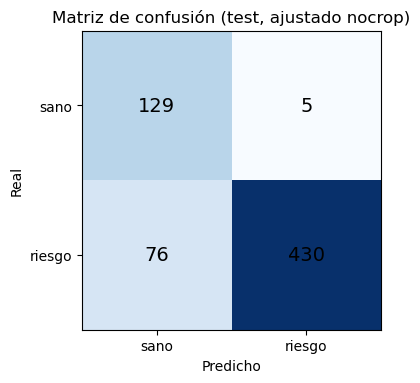

In [9]:
tuned_predictions = predictions[TUNED_NOCROP_NAME]
tuned_threshold = tuned_predictions["threshold"]
test_predicted_labels = (tuned_predictions["test_probabilities"] >= tuned_threshold).astype(int)

print(f"Modelo ajustado nocrop, TEST, umbral={tuned_threshold:.3f} (elegido en validación)\n")
print(
    classification_report(
        tuned_predictions["test_labels"].astype(int),
        test_predicted_labels,
        target_names=["sano (0)", "riesgo (1)"],
        digits=4,
    )
)

confusion = compute_classification_metrics(
    tuned_predictions["test_probabilities"], tuned_predictions["test_labels"], tuned_threshold
)["confusion_matrix"]
figure, axis = plt.subplots(figsize=(4, 4))
axis.imshow(confusion, cmap="Blues")
for row in range(2):
    for column in range(2):
        axis.text(column, row, confusion[row][column], ha="center", va="center", fontsize=14)
axis.set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["sano", "riesgo"], yticklabels=["sano", "riesgo"],
    xlabel="Predicho", ylabel="Real", title="Matriz de confusión (test, ajustado nocrop)",
)
plt.tight_layout()
plt.savefig(figures_dir / "tuned_nocrop_confusion_matrix_test.png", dpi=110)
plt.show()

## 4. Grad-CAM del modelo ajustado nocrop (test)

Mismo método que en `02_train_resnet152_nocrop.ipynb` (`src/explain.py`, hooks sobre `layer4[-1]`) y con el mismo letterbox que el modelo (`preprocessing=tuned_nocrop_config.preprocessing`). Se usa el umbral elegido en validación para definir TP / TN / FP / FN; se muestran los cuatro ejemplos más confiados de cada grupo. Figuras en `artifacts/gradcam/nocrop/tuned_*.png`.

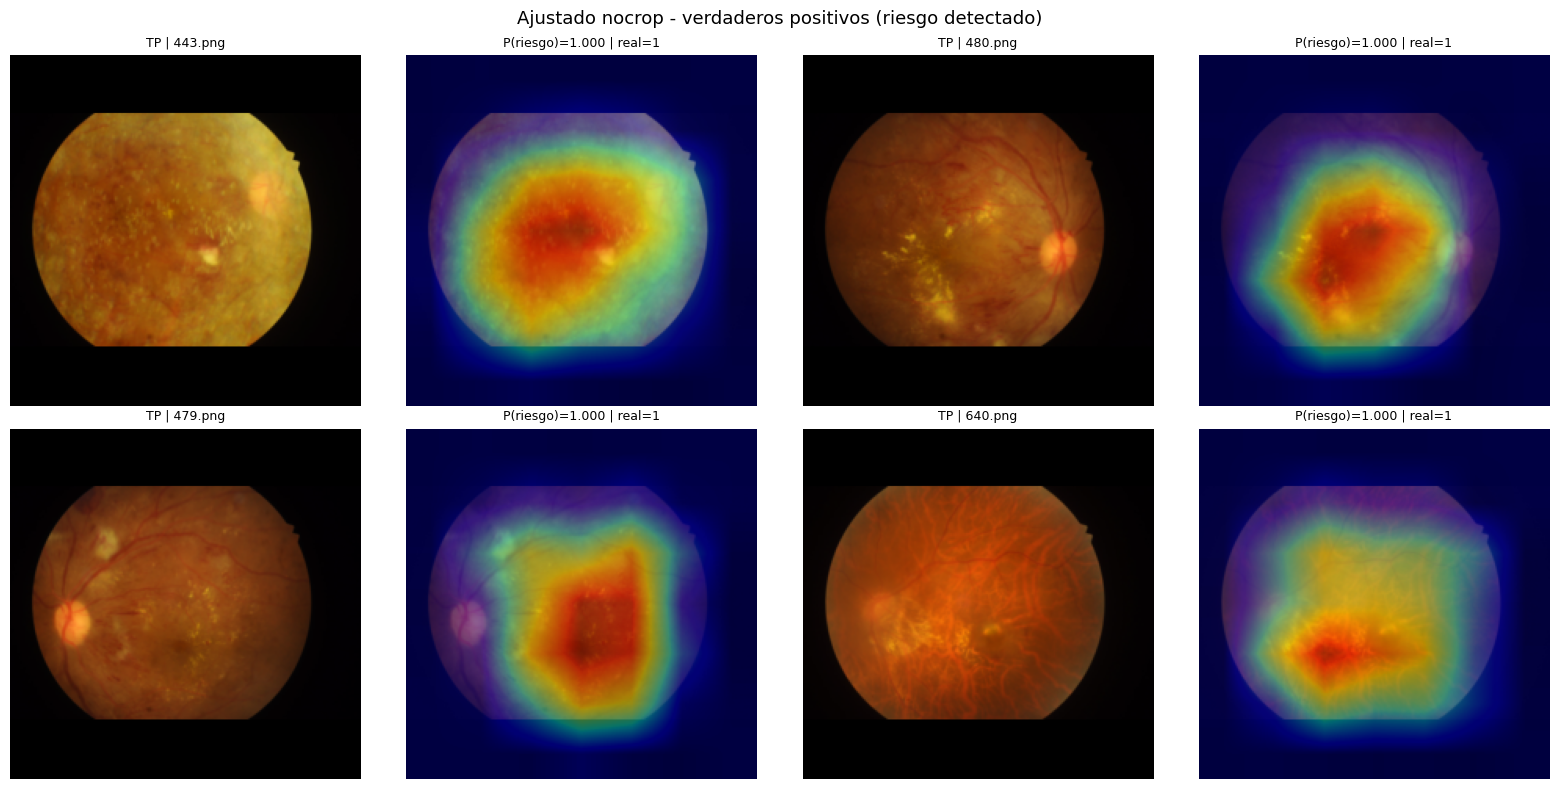

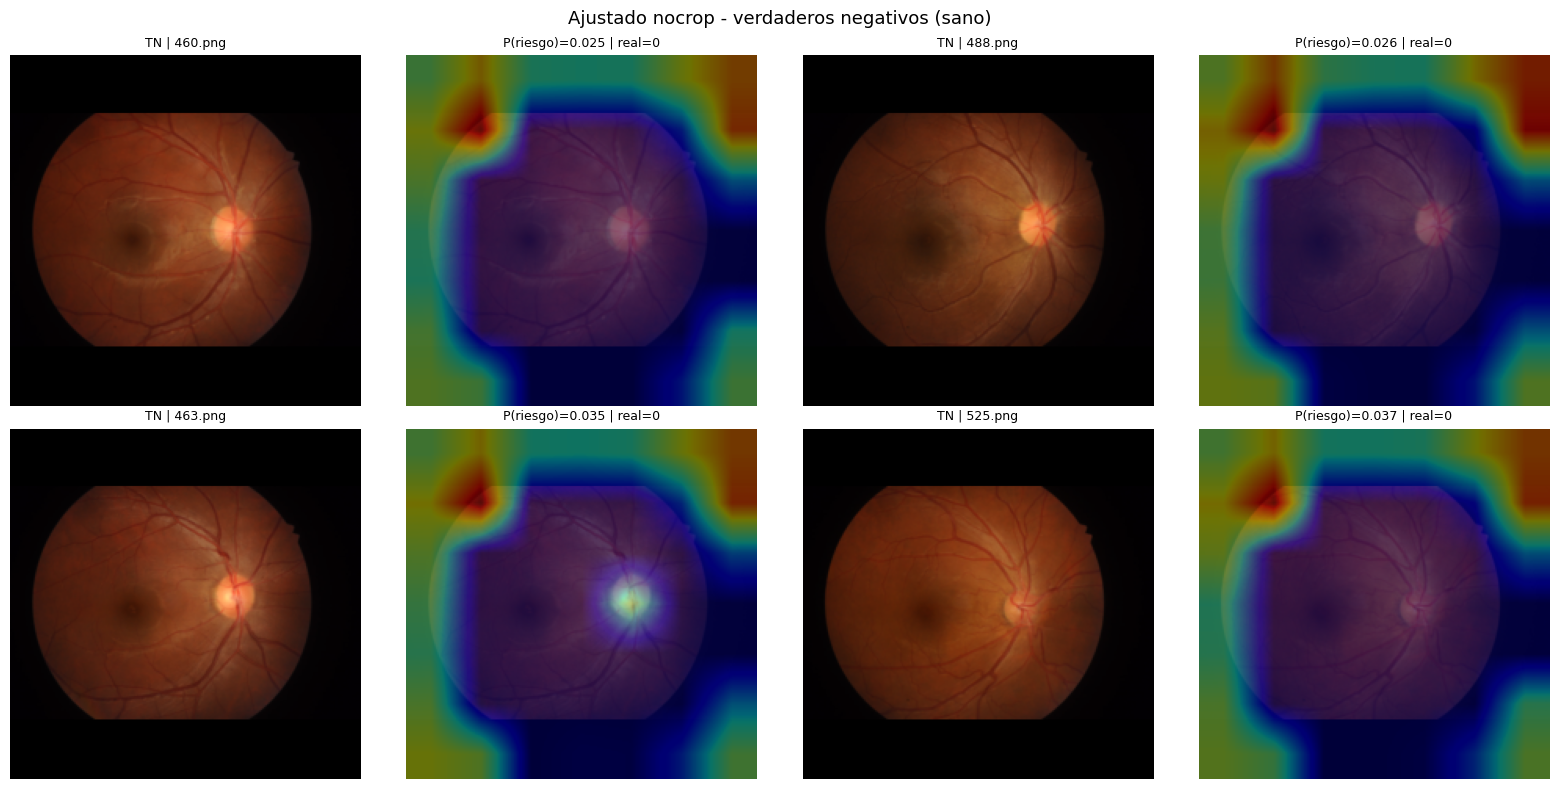

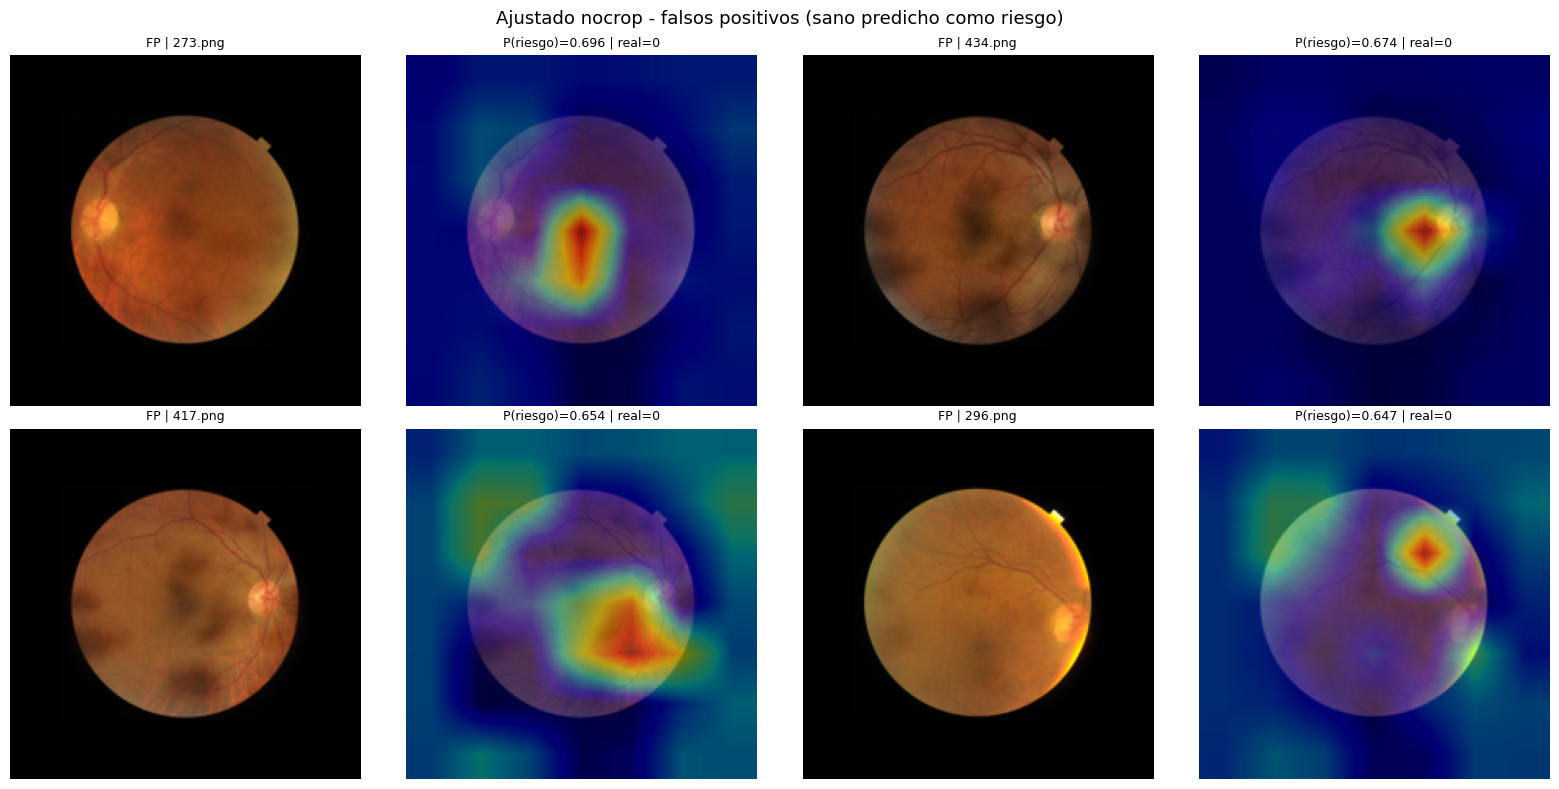

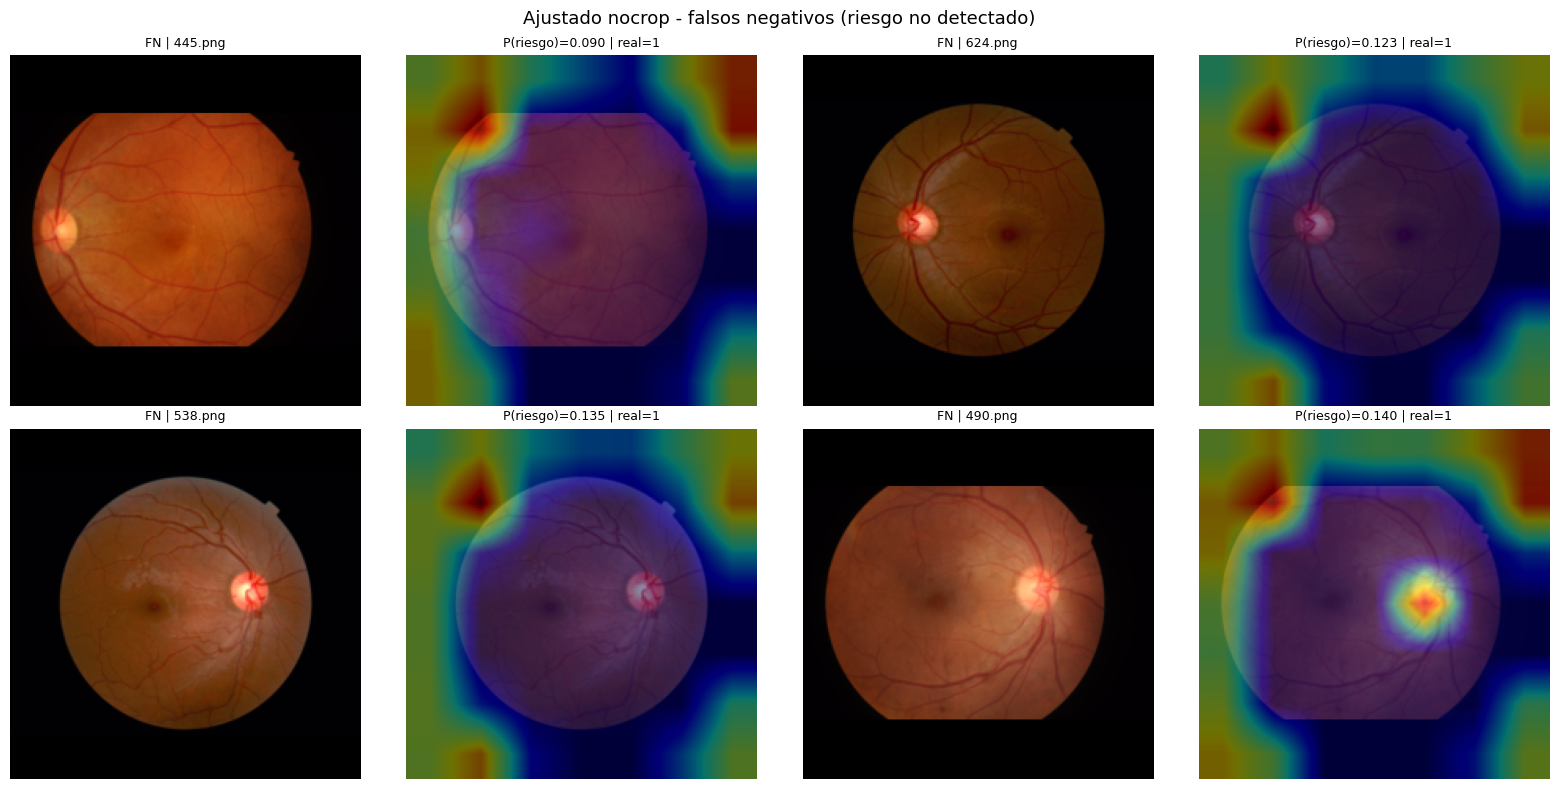

In [10]:
GRADCAM_DIR = PROJECT_ROOT / "artifacts" / "gradcam" / "nocrop"

gradcam_samples = compute_gradcam_samples(
    tuned_model,
    test_dataframe,
    tuned_predictions["test_probabilities"],
    tuned_predictions["test_labels"],
    threshold=tuned_threshold,
    image_size=tuned_nocrop_config.image_size,
    examples_per_group=4,
    preprocessing=tuned_nocrop_config.preprocessing,
)
group_titles = {
    "TP": "Ajustado nocrop - verdaderos positivos (riesgo detectado)",
    "TN": "Ajustado nocrop - verdaderos negativos (sano)",
    "FP": "Ajustado nocrop - falsos positivos (sano predicho como riesgo)",
    "FN": "Ajustado nocrop - falsos negativos (riesgo no detectado)",
}
for group, group_title in group_titles.items():
    group_samples = [s for s in gradcam_samples if s["group"] == group]
    figure = plot_gradcam_grid(
        group_samples, title=group_title, save_path=GRADCAM_DIR / f"tuned_{group}.png"
    )
    if figure is not None:
        plt.show()